In [149]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erf

In [150]:
n_samples = 500

theta_max = 50
t_min = -70

d_1 = 15
d_2 = 40

theta = np.linspace(-theta_max, theta_max, n_samples)
t     = np.linspace(-t_min,   0, n_samples)

extent = [-theta_max, theta_max, t_min, 0]

THETA, T = np.meshgrid(theta, t)
ONE = np.ones_like(THETA)

Text(0.5, 1.0, 'Prior')

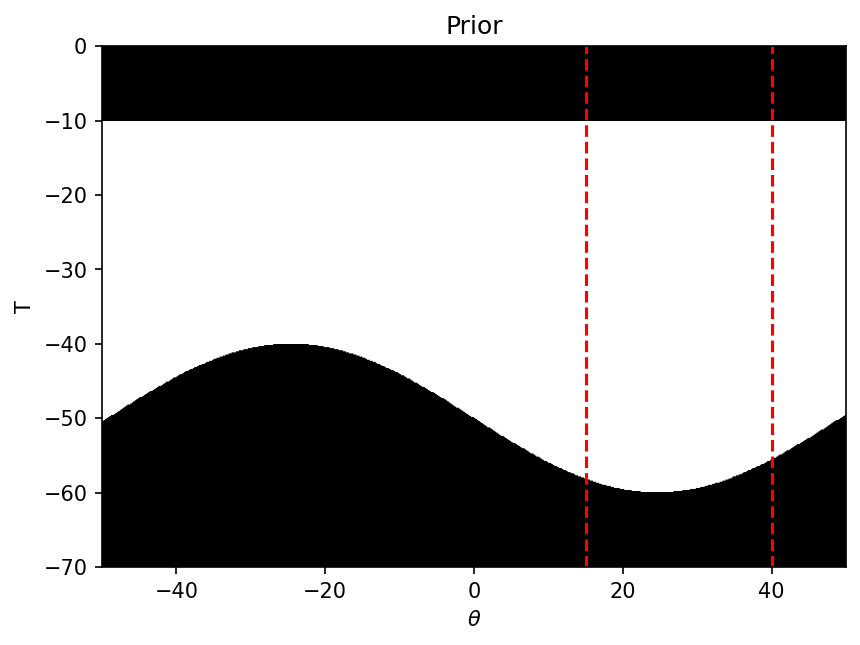

In [190]:
plt.figure(dpi=150)
PRIOR = (np.sin(THETA/np.pi/5)*10 > T - 50) & (T > 10)
PRIOR = PRIOR.astype(float)
plt.axvline(d_1, c='r', ls='--')
plt.axvline(d_2, c='r', ls='--')
plt.imshow(PRIOR, origin='lower', extent=extent, cmap="Greys_r")
plt.xlabel(r"$\theta$")
plt.ylabel("T")
plt.title("Prior")

~\AppData\Local\Temp\ipykernel_21776\808883808.py:2: RuntimeWarning: divide by zero encountered in divide
  return erf((THETA + 5 - d + v_drift * T)/(T * diffusivity)) - erf((THETA - 5 - d + v_drift * T)/(T * diffusivity))


Text(0.5, 1.0, 'Likelihood')

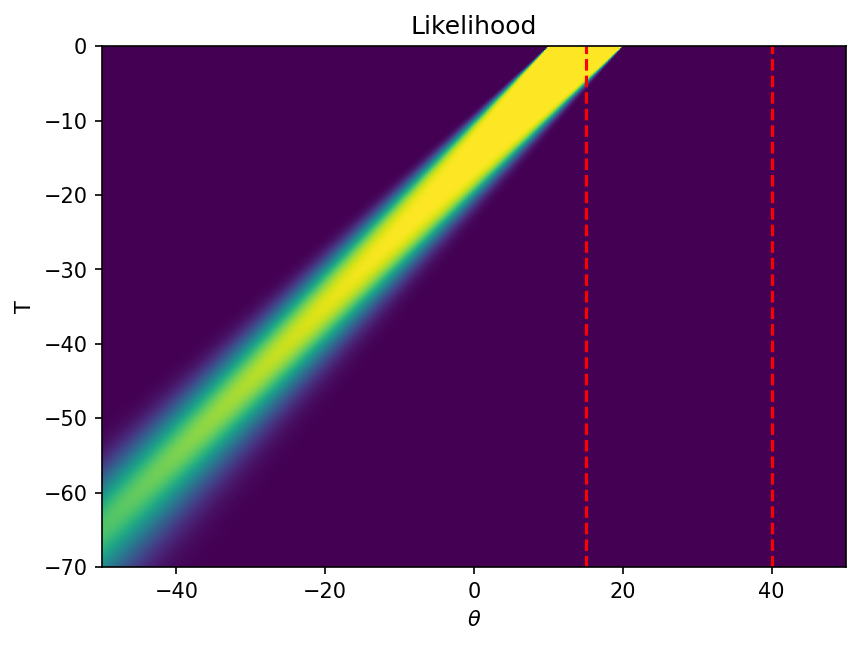

In [182]:
def likelihood(d, T, THETA, v_drift, diffusivity):
    return erf((THETA + 5 - d + v_drift * T)/(T * diffusivity)) - erf((THETA - 5 - d + v_drift * T)/(T * diffusivity))
plt.figure(dpi=150)
LIKE = likelihood(d_1, T, THETA, 1, 0.1)# * likelihood(d_2, T, THETA, 1, 0.5)
plt.axvline(d_1, c='r', ls='--')
plt.axvline(d_2, c='r', ls='--')
plt.imshow(LIKE, origin='lower', extent=extent)
plt.xlabel(r"$\theta$")
plt.ylabel("T")
plt.title("Likelihood")

Text(0.5, 1.0, 'Posterior (single bubble)')

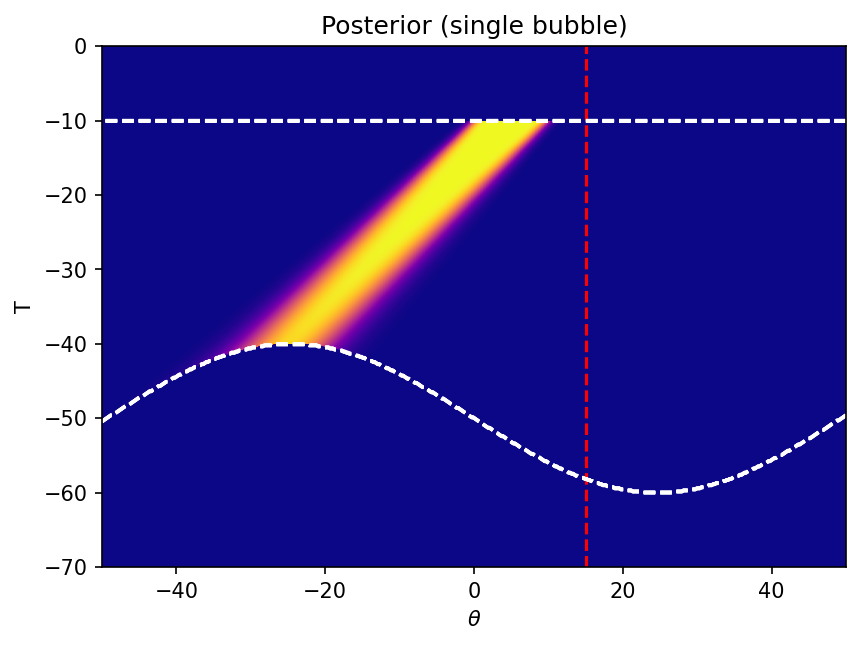

In [183]:
plt.figure(dpi=150)
plt.axvline(d_1, c='r', ls='--')
#plt.axvline(d_2, c='r', ls='--')
plt.imshow(LIKE*PRIOR, origin='lower', extent=extent, cmap='plasma')
plt.contour(PRIOR, extent=extent, linestyles=['--'], colors=['w'])
plt.xlabel(r"$\theta$")
plt.ylabel("T")
plt.title("Posterior (single bubble)")

~\AppData\Local\Temp\ipykernel_21776\808883808.py:2: RuntimeWarning: divide by zero encountered in divide
  return erf((THETA + 5 - d + v_drift * T)/(T * diffusivity)) - erf((THETA - 5 - d + v_drift * T)/(T * diffusivity))


Text(0.5, 1.0, 'Posterior (two bubbles)')

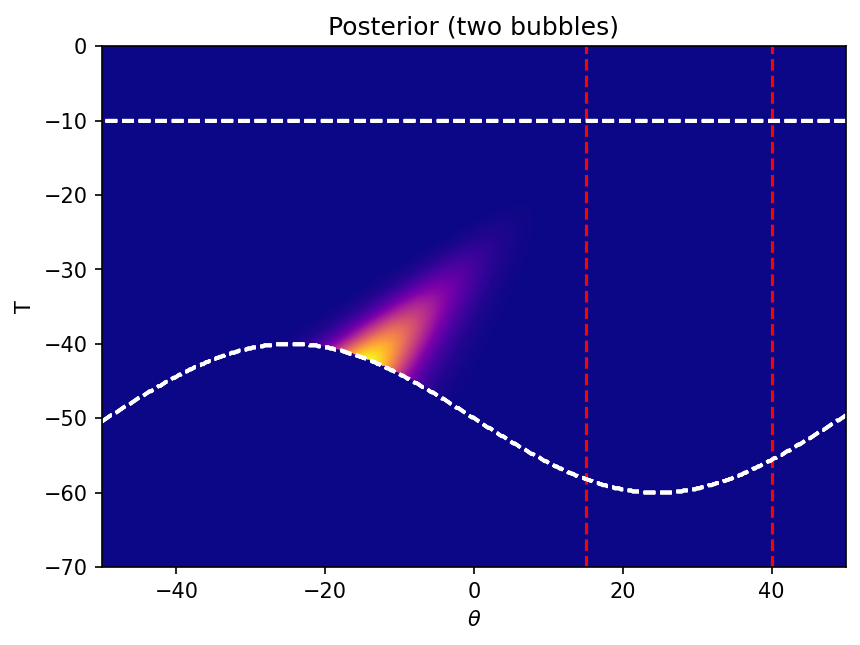

In [184]:
LIKE = likelihood(d_1, T, THETA, 1, 0.2) * likelihood(d_2, T, THETA, 1, 0.2)
plt.figure(dpi=150)
plt.axvline(d_1, c='r', ls='--')
plt.axvline(d_2, c='r', ls='--')
plt.imshow(LIKE*PRIOR, origin='lower', extent=extent, cmap='plasma')
plt.contour(PRIOR, extent=extent, linestyles=['--'], colors=['w'])
plt.xlabel(r"$\theta$")
plt.ylabel("T")
plt.title("Posterior (two bubbles)")

~\AppData\Local\Temp\ipykernel_21776\808883808.py:2: RuntimeWarning: divide by zero encountered in divide
  return erf((THETA + 5 - d + v_drift * T)/(T * diffusivity)) - erf((THETA - 5 - d + v_drift * T)/(T * diffusivity))


Text(0.5, 1.0, 'Likelihood Sum')

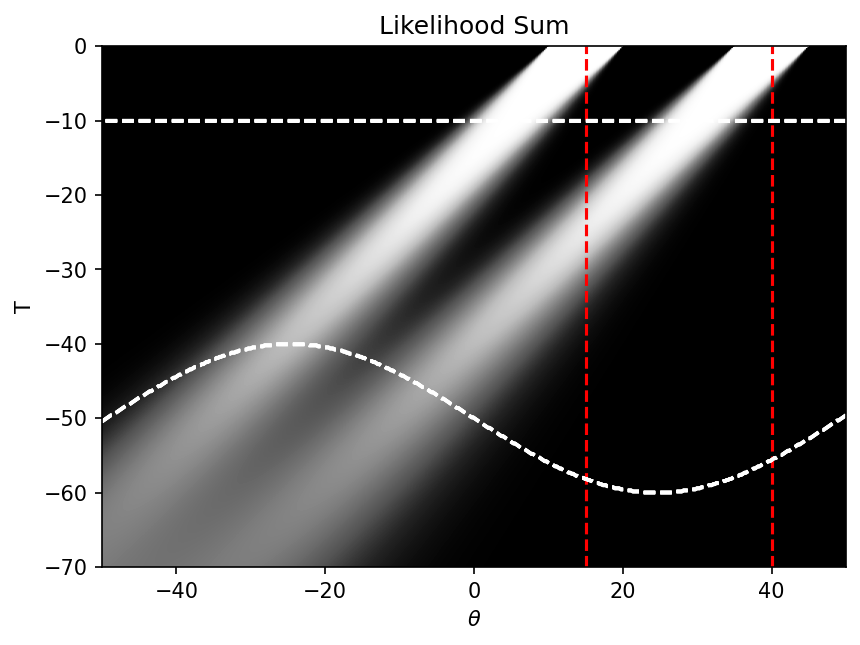

In [187]:
LIKE = likelihood(d_1, T, THETA, 1, 0.2) + likelihood(d_2, T, THETA, 1, 0.2)
plt.figure(dpi=150)
plt.axvline(d_1, c='r', ls='--')
plt.axvline(d_2, c='r', ls='--')
plt.imshow(LIKE, origin='lower', extent=extent, cmap='Greys_r')
plt.contour(PRIOR, extent=extent, linestyles=['--'], colors=['w'])
plt.xlabel(r"$\theta$")
plt.ylabel("T")
plt.title("Likelihood Sum")